# Airline passengers — SARIMA with makystats

**Dataset.** Classic Box & Jenkins monthly airline passenger series (Jan 1949 – Dec 1960, 144 observations): thousands of international passengers.

**Goal.** Fit a seasonal ARIMA model on the log series with `makystats.arma`, interpret coefficients and diagnostics, then compare candidates with `select_arma_order`.

**Why this series?** Strong trend, strong yearly seasonality (s = 12), and heteroskedasticity in levels — the textbook motivation for **log + seasonal differencing**.

**Requirements.** `makystats >= 0.1.3`, `pandas`, `numpy`, `matplotlib`.


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from makystats import arma, select_arma_order

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["axes.titlesize"] = 12


## 2. Load and inspect the series

The CSV ships next to this notebook under `data/`. The index is a monthly `DatetimeIndex`.


In [2]:
df = pd.read_csv("data/airline_passengers.csv", index_col=0)
df.index = pd.to_datetime(df.index)
y = df["Thousands of Passengers"].astype(float)
y.name = "passengers"

print(y.index.min().date(), "→", y.index.max().date(), f"({len(y)} obs.)")
y.describe().round(1)


1949-01-01 → 1960-12-01 (144 obs.)


count    144.0
mean     280.3
std      120.0
min      104.0
25%      180.0
50%      265.5
75%      360.5
max      622.0
Name: passengers, dtype: float64

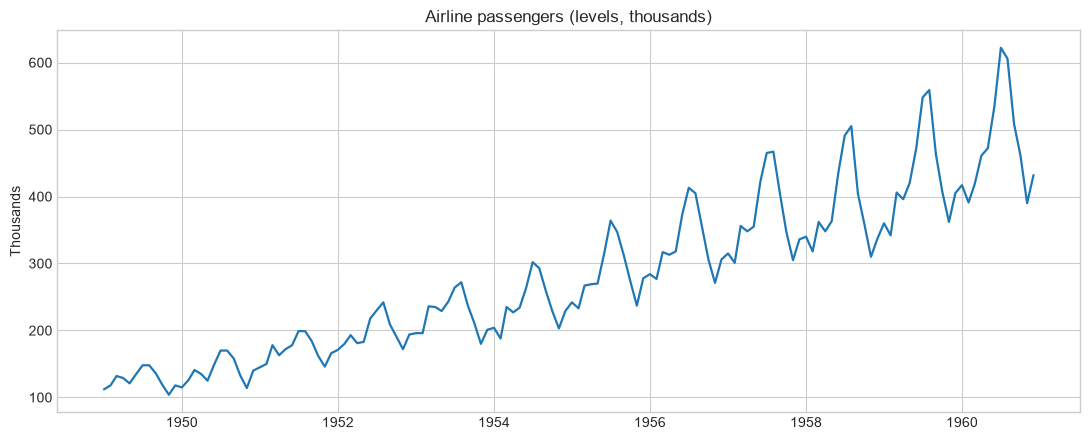

In [3]:
fig, ax = plt.subplots()
ax.plot(y, color="C0", lw=1.6)
ax.set_title("Airline passengers (levels, thousands)")
ax.set_ylabel("Thousands")
ax.set_xlabel("")
fig.tight_layout()
plt.show()


### Reading the levels plot

- **Trend:** clear upward movement over 1949–1960 (post-war growth of air travel).
- **Seasonality:** peaks in northern-hemisphere summer (around July–August), troughs in winter.
- **Variance:** seasonal amplitude **grows** with the level → multiplicative seasonality.

Working in **logarithms** turns multiplicative effects into additive ones and stabilises the variance — standard practice on this series.


## 3. Log transform


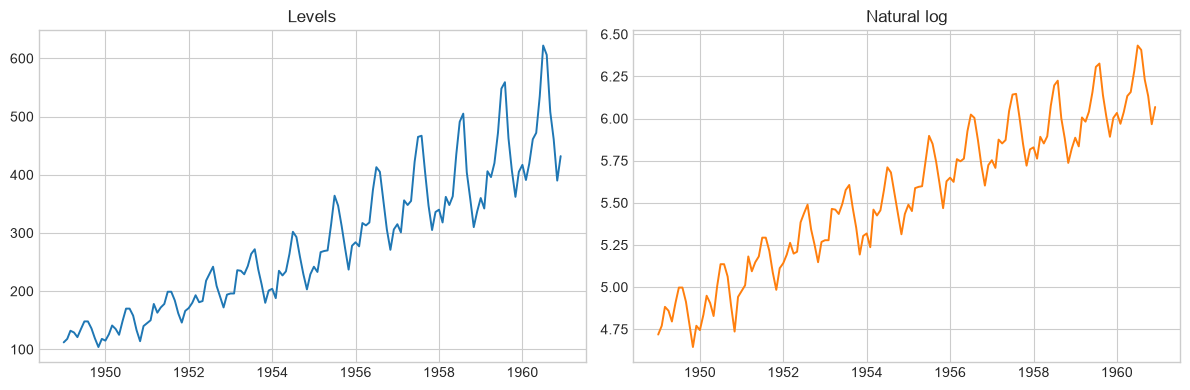

In [4]:
ylog = np.log(y)
ylog.name = "log_passengers"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(y, color="C0", lw=1.4)
axes[0].set_title("Levels")
axes[1].plot(ylog, color="C1", lw=1.4)
axes[1].set_title("Natural log")
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
plt.show()


## 4. Model specification

A widely used specification for this series is:

\[
\text{SARIMA}(0,1,1)\times(1,1,1)_{12}
\]

on \(\log y_t\), with a constant on the differenced scale (`trend="c"`).

| Component | Role |
|-----------|------|
| \(d = 1\) | Removes the stochastic trend in the log series |
| \(D = 1\), \(s = 12\) | Seasonal difference once per year |
| MA(1) | Short-run shock smoothing after regular differencing |
| SMA(12) | Seasonal moving-average correction |
| SAR(12) | Seasonal AR (often small on this sample) |

In makystats this is:

```python
arma(ylog, mean="ARMA", ar=0, ma=1, d=1,
     seasonal_order=(1, 1, 1, 12), trend="c")
```


## 5. Estimation


In [7]:
model = arma(
    ylog,
    mean="ARMA",
    ar=0,
    ma=1,
    d=1,
    seasonal_order=(1, 1, 1, 12),
    trend="c",
)
res = model.fit(verbose=False)
print(res.summary())


                               SARIMAX Results                                
Dep. Variable:          log_passengers   No. Observations:              144
Model:          SARIMAX(0,1,1)x(1,1,1,12)
                                         Log Likelihood:            244.967
Date:                 Tue, 27 Oct 2026   AIC:                      -479.934
Time:                         11:07:00   BIC:                      -465.558
Sample:                     1949-01-01   HQIC:                     -473.900
                          - 1960-12-01                                     
Covariance Type:                   opg                                     
                      coef   std err         z     P>|z|    [0.025    0.975]
------------------------------------------------------------------------------
const              -0.0002    0.0012   -0.1562     0.876   -0.0024    0.0021
ma.L1              -0.4151    0.0735   -5.6446     0.000   -0.5592   -0.2709
ar.S.L12           -0.1107    0.1884 

### Coefficient interpretation (typical pattern on this sample)

Exact numbers depend on the optimiser run, but the **signs and significance** are stable:

- **MA(1)** usually **negative and significant**: after first differencing, positive shocks are partly offset the next month (mean-reverting noise).
- **SMA(12)** usually **negative and significant**: seasonal MA absorbs the annual pattern left after seasonal differencing.
- **SAR(12)** is often **small / insignificant** on 144 monthly points — the seasonal MA already carries much of the yearly dynamics.
- **const** on the differenced scale is typically near zero: once \(d=D=1\), little residual drift remains.
- **\(\sigma^2\)** is the innovation variance on the **differenced log** scale (not passenger counts).

Information criteria (AIC/BIC) are comparable across models only when estimated on the **same transformed sample** (same \(d\), \(D\), \(s\)), which `select_arma_order` enforces.


## 6. Residuals and diagnostics


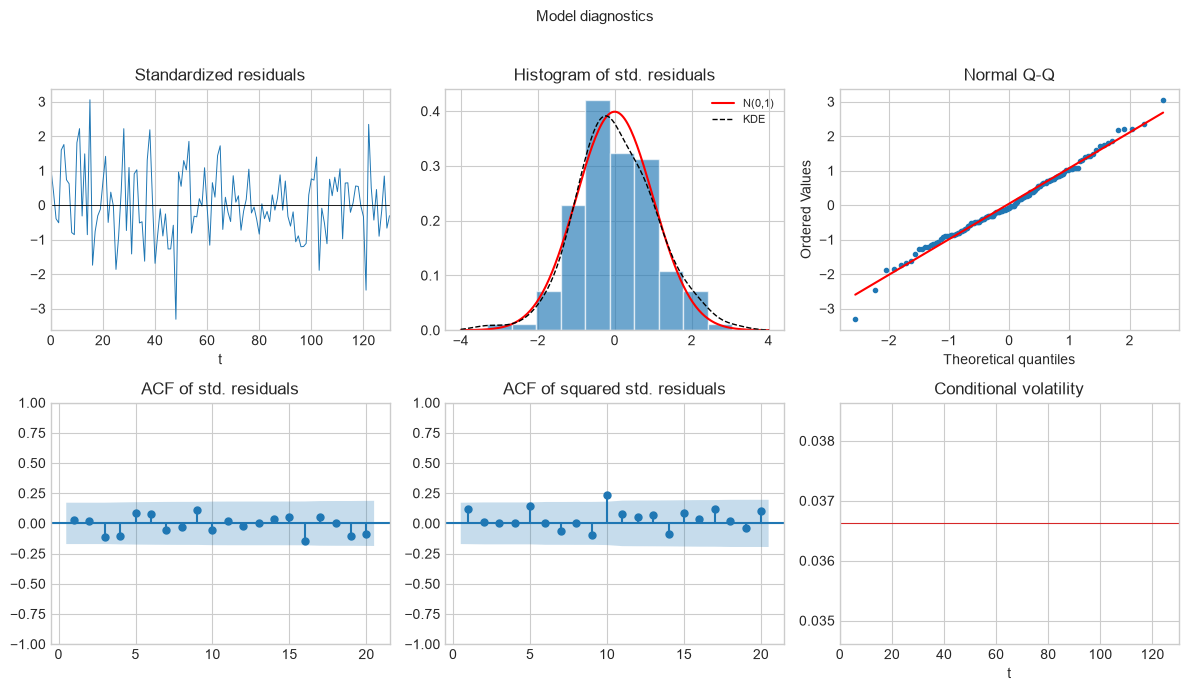

In [8]:
fig = res.plot_diagnostics()
plt.show()


### What to look for

- **Residual path:** should look like noise around zero after the burn-in implied by \(d\) and \(D\).
- **Histogram / QQ:** mild excess kurtosis is common on short seasonal samples; large systematic skew would be more worrying.
- **ACF of residuals:** remaining spikes at lag 12 (or multiples) would suggest under-modelled seasonality.
- **ACF of squared residuals:** patterns here would motivate a GARCH layer (`arma_garch`); for pure mean modelling, ARMA is enough if serial correlation in levels is gone.


In [9]:
# Ljung–Box test on residuals (serial correlation)
# Prefer the method API; attributes ljungbox_resid* may be unset (None) until computed.
lb = res.test_serial_correlation(lags=12)
print(lb)
# Rule of thumb: p-values >> 0.05 → no strong evidence of leftover autocorrelation
# at those lags (after accounting for estimated ARMA parameters when df_adjust=True).


     lb_stat  lb_pvalue
1   0.076867   0.781588
2   0.126347   0.722251
3   1.977048   0.159702
4   3.509779   0.061008
5   4.476753   0.106631
6   5.396262   0.144977
7   5.778986   0.216273
8   5.890032   0.317067
9   7.632072   0.266316
10  8.028689   0.330071
11  8.104799   0.423301
12  8.150737   0.519030


## 7. Fitted values in levels

`fitted_values_level()` reconstructs the series on the **log** scale (inverse of the internal differencing). Exponentiate to compare with original passenger counts. Early observations are `NaN` while lags fill (regular + seasonal differences).


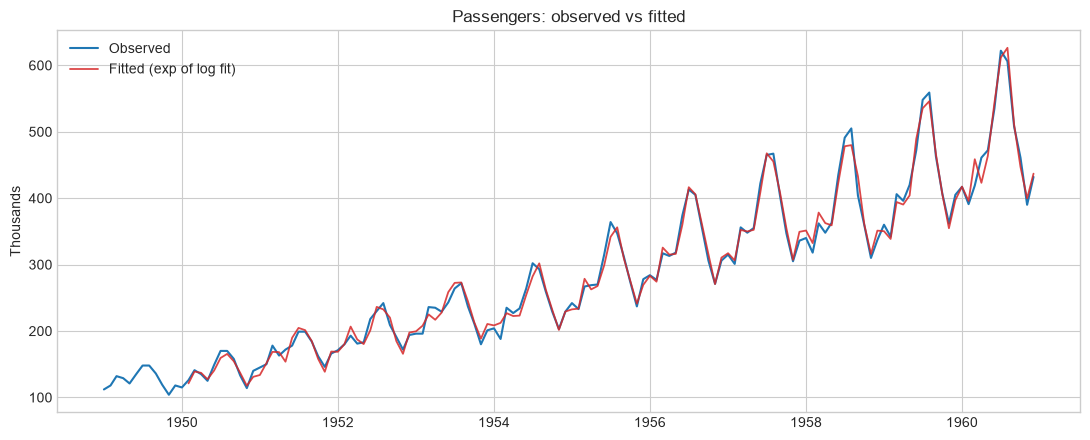

RMSE (levels, overlapping sample): 10.72 thousand passengers


In [10]:
fitted_log = res.fitted_values_level()
fitted_level = np.exp(fitted_log)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(y, label="Observed", color="C0", lw=1.5)
ax.plot(fitted_level, label="Fitted (exp of log fit)", color="C3", lw=1.3, alpha=0.85)
ax.set_title("Passengers: observed vs fitted")
ax.set_ylabel("Thousands")
ax.legend()
fig.tight_layout()
plt.show()

# In-sample fit quality on overlapping sample
mask = fitted_level.notna()
rmse = np.sqrt(np.mean((y[mask] - fitted_level[mask]) ** 2))
print(f"RMSE (levels, overlapping sample): {rmse:.2f} thousand passengers")


The fitted path should track the seasonal peaks and the secular rise. Large misses concentrated in one season would suggest a richer seasonal MA/AR or calendar effects (not modelled here).


## 8. Order selection with fixed seasonality

Hold `seasonal_order=(1,1,1,12)` and `d=1` fixed; search non-seasonal \(p,q \in \{0,\ldots,3\}\) by AIC (or BIC for stronger parsimony).


In [11]:
table, best = select_arma_order(
    ylog,
    p_range=range(0, 4),
    q_range=range(0, 4),
    d=1,
    seasonal_order=(1, 1, 1, 12),
    criterion="aic",
    return_best=True,
    verbose=False,
)
table.head(8)


,p,q,aic,bic,hqic,loglik,sigma2,n_obs,n_params,ok
"ARMA(0,1)+S(1,1,1)[12]",0,1,-479.933890,-465.557903,-473.900067,244.966945,0.001341,144,5,True
"ARMA(2,3)+S(1,1,1)[12]",2,3,-478.898603,-453.021827,-468.037722,248.449302,0.001270,144,9,True
"ARMA(0,3)+S(1,1,1)[12]",0,3,-478.822197,-458.695816,-470.374845,246.411099,0.001309,144,7,True
"ARMA(0,2)+S(1,1,1)[12]",0,2,-478.128706,-460.877522,-470.888119,245.064353,0.001337,144,6,True
"ARMA(1,0)+S(1,1,1)[12]",1,0,-477.743317,-463.367330,-471.709494,243.871658,0.001363,144,5,True
"ARMA(1,1)+S(1,1,1)[12]",1,1,-477.135556,-459.884372,-469.894969,244.567778,0.001341,144,6,True
"ARMA(3,3)+S(1,1,1)[12]",3,3,-476.928044,-448.176070,-464.860398,248.464022,0.001264,144,10,True
"ARMA(2,0)+S(1,1,1)[12]",2,0,-476.445865,-459.194681,-469.205278,244.222932,0.001356,144,6,True


In [12]:
print("Best by AIC:", table.index[0])
print(best.summary())


Best by AIC: ARMA(0,1)+S(1,1,1)[12]
                               SARIMAX Results                                
Dep. Variable:          log_passengers   No. Observations:              144
Model:          SARIMAX(0,1,1)x(1,1,1,12)
                                         Log Likelihood:            244.967
Date:                 Tue, 27 Oct 2026   AIC:                      -479.934
Time:                         11:09:50   BIC:                      -465.558
Sample:                     1949-01-01   HQIC:                     -473.900
                          - 1960-12-01                                     
Covariance Type:                   opg                                     
                      coef   std err         z     P>|z|    [0.025    0.975]
------------------------------------------------------------------------------
const              -0.0002    0.0012   -0.1562     0.876   -0.0024    0.0021
ma.L1              -0.4151    0.0735   -5.6446     0.000   -0.5592   -0.2709
a

### How to read the selection table

- Rows share the same \(d\) and seasonal block → **AIC/BIC are comparable**.
- The classic \((0,1,1)\times(1,1,1)_{12}\) often ranks near the top on AIC; BIC may prefer an even leaner non-seasonal part.
- Prefer **parsimony** when several models are within ~2 AIC points: extra AR/MA lags rarely improve out-of-sample seasonal forecasts on this length of sample.
- `return_best=True` refits the winning specification so you can reuse `summary()`, diagnostics, and forecasts immediately.


## 9. Short outlook (optional)

Multi-step forecasts are returned in **levels of the modelled series** (here: log-passengers) when \(d\) or \(D\) > 0. Exponentiate for passenger counts. Prediction intervals on the log scale become asymmetric once mapped back to levels — appropriate for a multiplicative series.


<class 'pandas.DataFrame'>
                mean
1961-01-01  6.110597
1961-02-01  6.053215
1961-03-01  6.174718
1961-04-01  6.197180
1961-05-01  6.232920


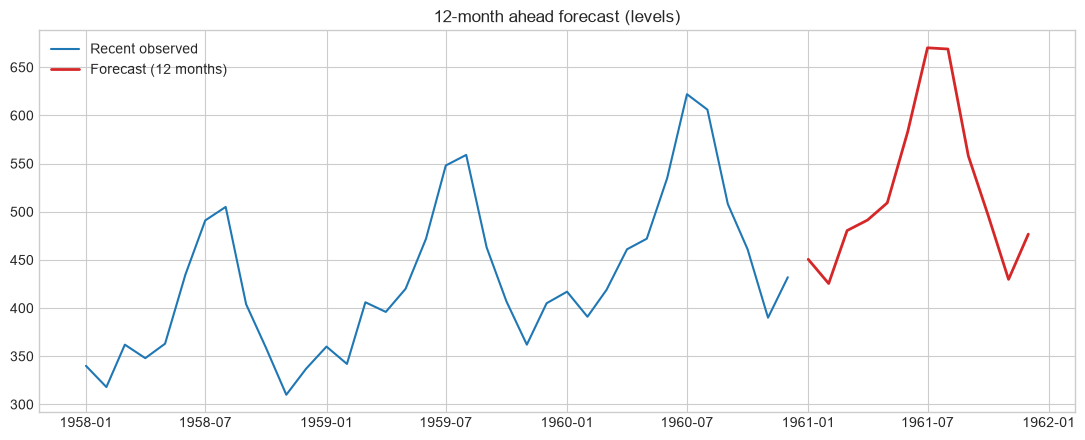

In [13]:
# Prefer the hand-specified SARIMA(0,1,1)x(1,1,1)12 for the illustration
fc = res.forecast(steps=12) if hasattr(res, "forecast") else None
if fc is not None:
    # forecast API may return DataFrame with mean / quantiles depending on version
    print(type(fc))
    print(fc.head() if hasattr(fc, "head") else fc)
    if isinstance(fc, pd.DataFrame) and "mean" in fc.columns:
        fc_passengers = np.exp(fc["mean"])
        fig, ax = plt.subplots()
        ax.plot(y.iloc[-36:], label="Recent observed", color="C0")
        ax.plot(fc_passengers, label="Forecast (12 months)", color="C3", lw=2)
        ax.set_title("12-month ahead forecast (levels)")
        ax.legend()
        fig.tight_layout()
        plt.show()
else:
    print("forecast() not available on this result object in the installed version.")


## 10. Takeaways

1. **Airline passengers** is the reference series for seasonal ARIMA: trend + annual cycle + variance growing with level.
2. **Log + \(d=1\) + \(D=1\)** addresses trend and seasonal unit roots in a transparent way.
3. **makystats** estimates the model with a SARIMAX-style summary, keeps **DatetimeIndex** on residuals and level fits, and offers **grid selection** with a fixed seasonal block.
4. For **volatility clustering** in residuals, switch to `arma_garch` with the same mean lags; for pure seasonal mean dynamics, ARMA/SARIMA is enough.

### References

- Box, G. E. P., & Jenkins, G. M. (1970/1976). *Time Series Analysis: Forecasting and Control*.
- Classic series also used throughout Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*.
